# Simulação de Epidemias em Redes
**Autores:** _Rafael Gontijo_, _Rudá Brandão_ &nbsp;|&nbsp; **Data:** _24/11/2026_ &nbsp;|&nbsp; **Prazo:** 24/11/2026

**Resumo.** Simulamos o SIS discreto em redes complexas. Na rede ER da Q1 ($N=2000$, $\langle k\rangle\approx20$), a epidemia persiste para $R_0>1$ e se extingue para $R_0\le1$, como prevê o campo médio. A prevalência simulada fica abaixo de $1-1/R_0$, e quase toda a diferença vem da linearização da probabilidade de infecção.


## Guia de uso do notebook (célula de estudo — removida no PDF)

**Convenção de tags** (View → Cell Toolbar → Tags):
| Tag | Efeito na exportação final |
|---|---|
| `study` | célula **removida** (rascunhos, anotações, checklists) |
| `hide-code` | código **oculto**, saída (figuras/tabelas) mantida |
| _(sem tag)_ | aparece normalmente |

**Orçamento de páginas (PDF):** 1 página por questão, sem contar anexos. Sugestão: Métodos + Declaração de IA ≤ 1 pág. (confirmar com o professor se contam); Q1, Q2, Q3 ≤ 1 pág. cada; código vai em anexo.

**Regras de ouro**
- Rodar sempre com *Restart & Run All* antes de exportar.
- Resultados pesados vão para `results/` (cache); o notebook relê do disco se existir.
- Toda figura: eixos rotulados, unidades, legenda, `savefig` em `figs/`.
- Nenhuma semente "solta": tudo derivado de `SEED_BASE` (seção 0).

**Checklist global**
- [ ] Declaração de IA preenchida
- [ ] Sementes informadas
- [ ] ⟨k⟩, ⟨k²⟩ medidos para cada rede (ER, SF)
- [ ] Declarado: rede fixa ou várias realizações
- [ ] 100 execuções por conjunto de parâmetros, T ≥ 500
- [ ] Extintas (fração + tempo típico), ρ(t) condicionado + faixa p10–p90 em cada caso
- [ ] Opcionais (+10%): Q1(d), média incondicional, 2.4

## Declaração de contribuição de IA
> _Obrigatório. Descrever **o que** a IA fez (ex.: sugestão de estrutura, depuração, otimização do simulador, revisão de texto), **em quais partes** e **como foi verificado/validado** pela dupla. Citar ferramenta/modelo._

- Ferramenta(s) usada(s): Claude
- Contribuição de LLM: Geração de template para o trabalho, revisão de texto, auxílio de pesquisa, formatação das tabelas/figuras do relatório e rascunho do resumo e conferência númerica da Questão 1 
- Validação feita pelos autores: Todas as implementações e contas foram feitas a mão

## 0. Configuração e reprodutibilidade

In [1]:
# Imports
import os, json, time, pickle, platform
import numpy as np
import scipy
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse.linalg import eigsh
from scipy.optimize import brentq
import pandas as pd
# TODO: demais imports (ex.: numba, pandas, tqdm)

In [2]:
# Parâmetros globais fixados pelo enunciado
N = 2_000               # número de nós (padrão = 10_000)
T = 500            		# horizonte (mínimo)
N_RUNS = 100       		# execuções por rede por conjunto de parâmetros
N_SEEDS_INFECTED = 5	# número inicial de infectados
T_AVG = 100        		# janela da prevalência quase-estacionária
EPS = 1e-3         		# alternativa do critério de extinção (Q3)

SEED_BASE = 42   		# SEED inicial para as simulações
# TODO: política de sementes (ex.: np.random.SeedSequence(SEED_BASE).spawn(...) por rede / por execução)

# Organização de arquivos
for d in ["figs", "results"]:
    os.makedirs(d, exist_ok=True)

In [3]:
# Estilo de figuras
plt.rcParams.update({
    # Tamanho e resolução
    "figure.figsize": (6.5, 2.4),     # largura útil da página; ajuste a altura por figura
    "figure.dpi": 110,                # exibição no notebook
    "savefig.dpi": 300,               # arquivo salvo / PDF final
    "savefig.bbox": "tight",          # corta margens em branco
    "figure.constrained_layout.use": True,  # evita rótulos sobrepostos

    # Fontes (legíveis em figura pequena)
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "mathtext.fontset": "cm",         # símbolos como β, μ, ρ* no estilo LaTeX
    "font.family": "serif",           # combina com o texto do PDF

    # Linhas e marcadores
    "lines.linewidth": 1.5,
    "lines.markersize": 4,

    # Eixos e grade
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # Legenda
    "legend.frameon": False,

    # Vetorial limpo no PDF (fontes editáveis, sem Type 3)
    "pdf.fonttype": 42,
})

In [4]:
# Registro de ambiente (vai para o relatório)
print("Python", platform.python_version(), "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| networkx", nx.__version__)
print("SEED_BASE =", SEED_BASE)
T_INICIO = time.time()  # início da execução, para o tempo total (célula final)

Python 3.14.10 | numpy 2.5.5 | scipy 1.18.0 | networkx 3.6.1
SEED_BASE = 42


### 0.1 Funções comuns (esqueleto — implementar)

In [5]:
# ---------- Avaliação de redes ----------
def medir_rede(G: nx.Graph):
    '''Retorna dict: <k>, <k^2>, k_min, k_max, n_componentes'''
    degrees = np.array([d for _, d in G.degree()], dtype=float)
    k_1 = np.mean(degrees)
    k_2 = np.mean(degrees ** 2)
    k_min = np.min(degrees)
    k_max = np.max(degrees)
    comps = nx.number_connected_components(G)

    return {
        '<k>': k_1,
        '<k^2>': k_2,
        'k_min': k_min,
        'k_max': k_max,
        'n_comps': comps,
        'lambda_1': eigsh(nx.to_scipy_sparse_array(G, format='csr'), k=1, which='LA',
                           return_eigenvectors=False)[0]
    }        

# ---------- Simulação SIS ----------
def step_sis(G: nx.Graph, beta: float, mu: float, rng):
	'''
	Executa um passo do SIS para a rede, retorna o número de sussetiveis e infectados após a atualização 
	'''

	states = nx.get_node_attributes(G, 'Estado')
	next_states = states.copy()

	for no, estado in states.items():
		if estado == 'I':
			if rng.random() < mu:
				next_states[no] = 'S'
				continue
		
		vizinhos_inf = sum(1 for vis in G.neighbors(no) if states[vis] == 'I')
		if vizinhos_inf > 0:
			if rng.random() < 1 - (1 - beta) ** vizinhos_inf:
				next_states[no] = 'I'

	nx.set_node_attributes(G, next_states, 'Estado')

	return sum(1 for s in next_states.values() if s == 'S'), sum(1 for s in next_states.values() if s == 'I')


def simular_sis(G: nx.Graph, beta: float, mu: float, T: int, rng, imunizados=None,
                n_inicial=N_SEEDS_INFECTED, return_seed_degrees=False):
	'''
	SIS discreto síncrono (estado do passo anterior).
	Retorna: serie I(t) (len T+1), t_extincao (ou None).
	Se return_seed_degrees=True, retorna tambem a lista com o grau dos vertices
	inicialmente infectados (importante para a analise de 3.1).
	'''
	g_sim = G.copy()

	if imunizados is not None:
		g_sim.remove_nodes_from(imunizados)

	nx.set_node_attributes(g_sim, {n:"S" for n in g_sim.nodes}, "Estado")
	infected_seeds = rng.choice(list(g_sim.nodes), size=min(n_inicial, g_sim.number_of_nodes()), replace=False)
	nx.set_node_attributes(g_sim, {n:'I' for n in infected_seeds}, 'Estado')

	graus_sementes = [g_sim.degree(n) for n in infected_seeds]

	infected_history = np.zeros(T+1)
	infected_history[0] = len(infected_seeds)

	for t in range(1, T+1):
		_, I = step_sis(g_sim, beta, mu, rng)
		if I == 0:
			if return_seed_degrees:
				return infected_history, t, graus_sementes
			return infected_history, t

		infected_history[t] = I

	if return_seed_degrees:
		return infected_history, None, graus_sementes
	return infected_history, None

# ---------- Estatísticas ----------
def resumir_execucoes(series, tempos_ext, populacao, T_avg=T_AVG):
	'''
	A partir das séries I(t) de várias execuções, retornar:
	frac_extintas, tempo_tipico_extincao, rho_cond(t) (média só dos sobreviventes),
	p10(t), p90(t), rho_estacionario (média dos últimos T_avg passos nos sobreviventes),
	e (opcional) média incondicional.
	'''
	rho_mtx = np.array(series).T / populacao
	nao_ext_mask = rho_mtx[-1] != 0
	frac_extintas = 1 - np.mean(nao_ext_mask)

	tempos_ext_limpo = [t for t in tempos_ext if t is not None]
	tempo_tipico_extincao = np.mean(tempos_ext_limpo) if tempos_ext_limpo else None
	tempo_mediano_extincao = np.median(tempos_ext_limpo) if tempos_ext_limpo else None
	
	if nao_ext_mask.any():
		rho_cond = np.mean(rho_mtx[:, nao_ext_mask], axis=1)
		p10, p90 = np.quantile(rho_mtx[:, nao_ext_mask], [.1, .9], axis=1)
	else:                                  # todas as execucoes extintas: sem sobreviventes para condicionar
		rho_cond = np.full(rho_mtx.shape[0], np.nan)
		p10, p90 = rho_cond.copy(), rho_cond.copy()

	rho_est = np.mean(rho_cond[-T_avg:])
	rho_geral = np.mean(rho_mtx[-T_avg:, :])

	return {
		'frac_extintas': frac_extintas,
		'tempo_tipico_extincao': tempo_tipico_extincao,
		'tempo_mediano_extincao': tempo_mediano_extincao,
		'rho_media_serie': rho_mtx.mean(axis=1),          # média incondicional (todas as execuções)
		'frac_ativas_serie': (rho_mtx > 0).mean(axis=1),  # fração de execuções ainda com infectados
		'rho_cond_media_serie': rho_cond,
		'rho_cond_p10_serie': p10,
		'rho_cond_p90_serie': p90,
		'rho_cond_media_tavg': rho_est,
		'rho_geral_media_tavg': rho_geral,
		'populacao': populacao,
		'n_amostras': rho_mtx.shape[1],
		'n_sobreviventes': int(nao_ext_mask.sum()),
		'tam_serie': rho_mtx.shape[0],
		'tavg': T_avg
	}

def rodar_lote(G, beta, mu, rng_seed, n_runs=N_RUNS, T=T, imunizados=None,
               n_inicial=N_SEEDS_INFECTED, cache_key=None, return_seed_degrees=False):
	'''
	Roda n_runs execuções; usa cache em results/ se cache_key existir.
	Retorna as séries completas e, se return_seed_degrees=True, a lista com os
	graus das sementes iniciais de cada execução.
	'''
	# TODO: implementar cache em results/

	rng = np.random.default_rng(rng_seed)
	series, tempos, graus = list(), list(), list()
	for _ in range(n_runs):
		saida = simular_sis(G, beta, mu, T, rng, imunizados, n_inicial, return_seed_degrees)
		if return_seed_degrees:
			s, t, gs = saida
			graus.append(gs)
		else:
			s, t = saida
		series.append(s)
		tempos.append(t)

	if return_seed_degrees:
		return series, tempos, graus
	return series, tempos

# ---------- Utilidades de saída ----------
def fmt(x, f):
    """Número com vírgula decimal, como nas tabelas do relatório; '—' se não houver valor."""
    return '—' if x is None or np.isnan(x) else format(x, f).replace('.', ',')

def salvar_fig(fig, nome):
    fig.savefig('figs/' + nome + '.png')

def plot_rho_cond(resumo, ax, rotulo):
	'''ρ(t) condicionado + faixa p10–p90.'''
	ax.plot(resumo['rho_cond_media_serie'], label='média')
	ax.plot(resumo['rho_cond_p10_serie'], label='quantil 10%', ls='--', lw=1.5)
	ax.plot(resumo['rho_cond_p90_serie'], label='quantil 90%', ls='--', lw=1.5)
	ax.fill_between(np.arange(resumo['tam_serie']), resumo['rho_cond_p10_serie'], resumo['rho_cond_p90_serie'], alpha=0.2)
	ax.set_title(rotulo)
	ax.set_ylabel(r'Prevalência $\rho (t)$')
	ax.set_xlabel(r'Tempo $t$')

	return

In [6]:
# Testes rápidos (sanidade) — antes de rodar em escala
rng_teste = np.random.default_rng(SEED_BASE)
K5 = nx.complete_graph(5)

# beta = 0 -> ninguém é infectado; com mu = 1 todos os sementes se recuperam no 1º passo
serie, t_ext = simular_sis(nx.cycle_graph(50), 0.0, 1.0, 10, rng_teste)
assert t_ext == 1 and serie[0] == N_SEEDS_INFECTED

# mu = 0 -> sem recuperação: I(t) nunca diminui e, com beta = 1, toda a rede conexa é infectada
serie, t_ext = simular_sis(nx.cycle_graph(50), 1.0, 0.0, 30, rng_teste)
assert t_ext is None and np.all(np.diff(serie) >= 0) and serie[-1] == 50

# Rede pequena conferida à mão (K5, 1 semente, beta = mu = 1): atualização síncrona faz I(t) alternar
# t=0: 1 infectado -> t=1: ele se recupera e os 4 vizinhos se infectam -> t=2: os 4 se recuperam e ele se reinfecta
serie, _ = simular_sis(K5, 1.0, 1.0, 4, rng_teste, n_inicial=1)
assert list(serie) == [1, 4, 1, 4, 1]

# Medidas da rede em K5: todo vértice tem grau 4
m = medir_rede(K5)
assert m['<k>'] == 4 and m['<k^2>'] == 16 and m['k_max'] == 4 and m['n_comps'] == 1

# Resumo: 2 execuções, uma extinta em t=2 e uma com I = N constante
r = resumir_execucoes([np.array([2., 1, 0, 0]), np.full(4, 5.)], [2, None], 5, T_avg=2)
assert r['frac_extintas'] == 0.5 and r['tempo_tipico_extincao'] == 2 and r['rho_cond_media_tavg'] == 1

# Mesma semente -> mesmas séries (reprodutibilidade dos lotes)
a, _ = rodar_lote(K5, 0.3, 0.2, SEED_BASE, n_runs=3, T=20)
b, _ = rodar_lote(K5, 0.3, 0.2, SEED_BASE, n_runs=3, T=20)
assert all(np.array_equal(x, y) for x, y in zip(a, b))
print('testes de sanidade OK')


testes de sanidade OK


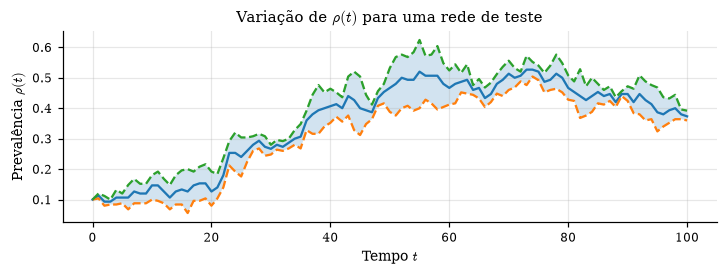

In [7]:
N_teste, p_teste = 50, 1/25
g_teste = nx.erdos_renyi_graph(N_teste, p_teste)
series_teste, tempos_teste = rodar_lote(g_teste, 0.1, 0.1, 0, 3, 100)
resumo_teste = resumir_execucoes(series_teste, tempos_teste, N_teste, 5)

f, a = plt.subplots()
plot_rho_cond(resumo_teste, a, r'Variação de $\rho(t)$ para uma rede de teste')
salvar_fig(f, 'teste_sanidade')

## 1. Métodos
**Modelo.** SIS discreto síncrono, $\Delta t = 1$; suscetível com $m$ vizinhos infectados infecta com prob. $1-(1-\beta)^m$; infectado recupera com prob. $\mu$. 5 infectados iniciais sorteados entre não imunizados.

**Tamanho da rede.** Usamos $N=2000$ em vez de $10^4$: na nossa máquina a Q1 levou ~16 min com $N=2000$, e o custo cresce linearmente com $N$, o que tornava $N=10^4$ inviável. Um $N$ menor aumenta as flutuações, mas não muda o regime.

**Redes geradas.** Q1: **rede ER fixa** (`fast_gnp_random_graph`, semente 42); as execuções do caso $i$ usam a semente $42+i$. Q2: _descrever método, sementes e tratamento de laços/arestas múltiplas._

**Execuções e observáveis.** 100 execuções por conjunto de parâmetros; $T = 500$; execução extinta se $I(t)=0$ para algum $t\le T$; prevalência estacionária = média de $\rho$ nos últimos 100 passos **apenas** nas execuções sobreviventes; faixa p10–p90.

**Reprodutibilidade.** Python 3.14.10, NumPy 2.5.5, SciPy 1.18.0, NetworkX 3.6.1, Matplotlib 3.11.2. Resultados em cache em `results/`; o tempo total da execução está na célula final.

| Rede | Método | $N$ | $\langle k\rangle$ | $\langle k^2\rangle$ | $k_{min}$–$k_{max}$ | $\lambda_1$ | Comp. |
|---|---|--|---|---|----|---|--|
| ER (Q1) | $G(N,p)$ | 2000 | 19,94 | 417,3 | 6–36 | 20,97 | 1 |

In [8]:
# Rede ER da Q1 (rede fixa). Linhas da tabela de redes: copiar a saída para a tabela em "1. Métodos"
k_1 = 20
G_er = nx.fast_gnp_random_graph(N, k_1 / (N - 1), seed=SEED_BASE)
medidas_er = medir_rede(G_er)

def linha_rede(nome, metodo, G, m):
    return (f"| {nome} | {metodo} | {G.number_of_nodes()} | {fmt(m['<k>'], '.2f')} | {fmt(m['<k^2>'], '.1f')} "
            f"| {m['k_min']:.0f}–{m['k_max']:.0f} | {fmt(m['lambda_1'], '.2f')} | {m['n_comps']} |")

print(linha_rede('ER (Q1)', '$G(N,p)$', G_er, medidas_er))
# TODO Q2: print(linha_rede('Livre de escala', 'modelo de configuração', g_erased, medir_rede(g_erased)))

| ER (Q1) | $G(N,p)$ | 2000 | 19,94 | 417,3 | 6–36 | 20,97 | 1 |


## 2. Questão 1 — Rede aleatória (Erdős–Rényi)
**Parâmetros:** $\langle k\rangle=20$, $\beta=0{,}02$; (a) $\mu=0{,}1$; (b) $\mu=0{,}3$; (c) $\mu=0{,}5$; (d, opcional) $\mu=0{,}4$.

### 2.1 Experimento
**Previsões antes de simular** (campo médio homogêneo):

| Caso | $\mu$ | $R_0=\beta\langle k\rangle/\mu$ | $\rho^*$ previsto |
|---|---|---|---|
| (a) | 0,1 |4|0,75|
| (b) | 0,3 |1,333|0,25|
| (c) | 0,5 |0,8|0,00|
| (d, opc.) | 0,4 | 1|0,00|

In [9]:
beta = 0.02
mus = [0.1, 0.3, 0.5, 0.4]
casos_q1 = dict(zip(['a', 'b', 'c', 'd'], mus))

teo_q1 = {}
for caso, mu in casos_q1.items():
    R0 = beta * k_1 / mu
    teo_q1[caso] = (R0, max(0, 1 - 1/R0))
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0, '.3f')} | {fmt(teo_q1[caso][1], '.2f')} |")
def rho_mf_exato(mu, graus):
    '''Ponto fixo de rho = (1-mu) rho + (1-rho) <1-(1-beta rho)^k>: campo médio sem linearizar a infecção.'''
    f = lambda r: -mu * r + (1 - r) * np.mean(1 - (1 - beta * r) ** graus)
    return brentq(f, 1e-9, 1) if f(1e-9) > 0 else 0.0

graus_er = np.array([d for _, d in G_er.degree()])
mf_exato_q1 = {caso: rho_mf_exato(mu, graus_er) for caso, mu in casos_q1.items()}
# 1-(1-x)^k <= kx: sem a linearização, o ponto fixo nunca fica acima de 1 - 1/R0
assert all(mf_exato_q1[c] <= teo_q1[c][1] + 1e-9 for c in casos_q1), mf_exato_q1
mf_exato_q1


| (a) | 0,1 | 4,000 | 0,75 |
| (b) | 0,3 | 1,333 | 0,25 |
| (c) | 0,5 | 0,800 | 0,00 |
| (d) | 0,4 | 1,000 | 0,00 |


{'a': 0.7119750445698425, 'b': 0.2150112505638275, 'c': 0.0, 'd': 0.0}

In [10]:
resumos_q1 = {}

for i, (caso, mu) in enumerate(casos_q1.items()):
    arq = f'results/q1_er_s{SEED_BASE}_mu{mu}_{beta}_T{T}_n{N_RUNS}.pkl'
    if os.path.exists(arq):
        with open(arq, 'rb') as f:
            series, tempos = pickle.load(f)
    else:
        series, tempos = rodar_lote(G_er, beta, mu, rng_seed=SEED_BASE + i, T=T)
        with open(arq, 'wb') as f:
            pickle.dump((series, tempos), f)
    resumos_q1[caso] = resumir_execucoes(series, tempos, N)

**Resultados por caso** ($N=2000$, 100 execuções, $T=500$). $t_{ext}$: média (mediana) entre as extintas; $\rho^*_{sim}$: últimos 100 passos das sobreviventes; MF exato: ponto fixo usando $1-(1-\beta\rho)^k$ em vez de $\beta k\rho$.

| Caso | $\mu$ | $R_0$ | Extintas | $t_{ext}$ média (mediana) | $\rho^*_{sim}$ | $\rho^*$ MF linear | $\rho^*$ MF exato |
|--|--|--|---|------|---|---|---|
| (a) | 0,1 | 4,00 | 0% | — | 0,705 | 0,750 | 0,712 |
| (b) | 0,3 | 1,33 | 18% | 15,2 (13,5) | 0,214 | 0,250 | 0,215 |
| (c) | 0,5 | 0,80 | 100% | 11,8 (9,0) | — | 0,000 | 0,000 |
| (d) | 0,4 | 1,00 | 100% | 47,6 (23,5) | — | 0,000 | 0,000 |


In [11]:
for caso, mu in casos_q1.items():
    r = resumos_q1[caso]
    R0, rho_teo = teo_q1[caso]
    t_ext = '—' if r['tempo_tipico_extincao'] is None else \
        f"{fmt(r['tempo_tipico_extincao'], '.1f')} ({fmt(r['tempo_mediano_extincao'], '.1f')})"
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0, '.2f')} | {fmt(100 * r['frac_extintas'], '.0f')}% | {t_ext} "
          f"| {fmt(r['rho_cond_media_tavg'], '.3f')} | {fmt(rho_teo, '.3f')} | {fmt(mf_exato_q1[caso], '.3f')} |")

| (a) | 0,1 | 4,00 | 0% | — | 0,705 | 0,750 | 0,712 |
| (b) | 0,3 | 1,33 | 18% | 15,2 (13,5) | 0,214 | 0,250 | 0,215 |
| (c) | 0,5 | 0,80 | 100% | 11,8 (9,0) | — | 0,000 | 0,000 |
| (d) | 0,4 | 1,00 | 100% | 47,6 (23,5) | — | 0,000 | 0,000 |


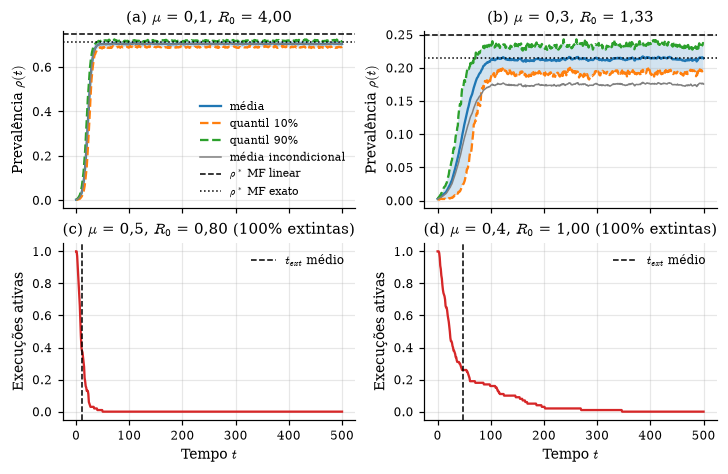

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(6.5, 4.2), sharex=True)
for ax, (caso, mu) in zip(axs.flat, casos_q1.items()):
    r = resumos_q1[caso]
    R0, rho_teo = teo_q1[caso]
    titulo = f'({caso}) $\\mu$ = {fmt(mu, "g")}, $R_0$ = {fmt(R0, ".2f")}'
    if r['frac_extintas'] < 1:
        plot_rho_cond(r, ax, titulo)
        ax.plot(r['rho_media_serie'], color='gray', lw=1, label='média incondicional')
        ax.axhline(rho_teo, color='k', ls='--', lw=1, label=r'$\rho^*$ MF linear')
        ax.axhline(mf_exato_q1[caso], color='k', ls=':', lw=1, label=r'$\rho^*$ MF exato')
        ax.set_xlabel('')
    else:
        ax.plot(r['frac_ativas_serie'], color='C3')
        ax.axvline(r['tempo_tipico_extincao'], color='k', ls='--', lw=1, label=r'$t_{ext}$ médio')
        ax.set_title(titulo + ' (100% extintas)')
        ax.set_ylabel('Execuções ativas')
        ax.set_xlabel(r'Tempo $t$')
        ax.legend()
axs[0, 0].legend(loc='lower right', fontsize=7)
salvar_fig(fig, 'q1_rho_cond')


**Discussão.**

- **Campo médio.** Acerta o regime nos quatro casos, mas superestima $\rho^*$ (0,705 × 0,750 em (a); 0,214 × 0,250 em (b)).
- **Tempo discreto.** O mapa troca $1-(1-\beta)^m$ por $\beta m$, contando infecções sobrepostas no mesmo passo. Sem essa linearização, o ponto fixo cai para 0,712 e 0,215: isso explica quase toda a diferença.
- **Correlações.** O resíduo em (a) vem de vizinhos de infectados estarem eles próprios infectados, o que o campo médio ignora.
- **5 sementes.** Em (b), 18% das execuções morrem cedo ($t\le31$): cada linhagem se extingue com prob. $\approx1/R_0$, e $0{,}75^5\approx0{,}24$.
- **(opc.) Caso crítico (d).** Extinção lenta, com cauda longa (mediana 23,5, máximo 347): o decaimento é algébrico, $\rho_t\approx\rho_0/(1+\mu\rho_0t)$. A fração de extintas depende de $T$ (16% ativas em $t=100$).
- **(opc.) Média incondicional.** Em (b), dá 0,175 $\approx0{,}82\cdot0{,}214$: mistura platô e extinção e não descreve nenhuma execução real.


### 2.2 Demonstração (campo médio homogêneo)
Mapa: $\rho_{t+1}=g(\rho_t)=\rho_t-\mu\rho_t+\beta\langle k\rangle\rho_t(1-\rho_t)$, $R_0=\beta\langle k\rangle/\mu$.

**(1) Pontos fixos.**

Um estado estacionário é um ponto fixo que satisfaz $\rho_{t+1} = \rho_t = \rho$, ou seja:

$$\rho = g(\rho) = \rho - \mu\rho + \beta\langle k \rangle\rho(1 - \rho)$$

Subtraindo $\rho$ de ambos os lados e fatorando, obtemos $\rho\left[-\mu + \beta\langle k \rangle(1 - \rho)\right] = 0$, o que fornece a solução trivial $\rho = 0$ (sempre válida em $[0, 1]$) e a solução não trivial $-\mu + \beta\langle k \rangle(1 - \rho^*) = 0$. 

Substituindo a definição $R_0 = \beta\langle k \rangle/\mu$, isolamos o ponto fixo endêmico $\rho^* = 1 - 1/R_0$. Quando $R_0 > 1$, temos $0 < 1/R_0 < 1$, garantindo que $\rho^* \in (0, 1)$ seja um segundo ponto fixo fisicamente válido; por outro lado, se $R_0 \le 1$, resulta que $1/R_0 \ge 1$ e, consequentemente, $\rho^* \le 0$ (fora do intervalo $(0, 1)$ ou coincidente com zero quando $R_0 = 1$), fazendo com que $\rho = 0$ seja o único ponto fixo do sistema em $[0, 1]$.


**(2) Estabilidade.** $g'(0)$, $g'(\rho^*)$, condição $\mu(R_0-1)<2$ e verificação nos casos da Q1.

Para analisar a estabilidade linear dos pontos fixos, derivamos $g(\rho)$ em relação a $\rho$, obtendo:

$$g'(\rho) = 1 - \mu + \beta\langle k \rangle(1 - 2\rho)$$

Avaliando no ponto fixo trivial $\rho = 0$ e substituindo $\beta\langle k \rangle = \mu R_0$, temos $g'(0) = 1 - \mu + \mu R_0 = 1 + \mu(R_0 - 1)$; como $\mu > 0$, para $R_0 > 1$ resulta $g'(0) > 1$, provando que $\rho = 0$ é linearmente instável. 

Já no ponto fixo endêmico $\rho^* = 1 - 1/R_0$, a derivada assume o valor $g'(\rho^*) = 1 - \mu + \mu R_0\left(1 - 2 + 2/R_0\right) = 1 - \mu(R_0 - 1)$. A condição de estabilidade assintótica $|g'(\rho^*)| < 1$ exige que $-1 < 1 - \mu(R_0 - 1) < 1$, o que equivale a $0 < \mu(R_0 - 1) < 2$. 

Verificando essa condição para os regimes com $R_0 > 1$ da Questão 1, obtemos $\mu(R_0 - 1) = 0{,}1 \cdot (4 - 1) = 0{,}3 < 2$ no caso (a) e $\mu(R_0 - 1) = 0{,}3 \cdot (4/3 - 1) = 0{,}1 < 2$ no caso (b), confirmando que $\rho^*$ é localmente estável em ambos os cenários.

**(3) Crescimento a partir de poucos infectados.** Se $R_0>1$ e $0<\rho_t<\rho^*$ então $\rho_{t+1}>\rho_t$.

Para demonstrar que a infecção cresce a partir de poucos infectados quando $R_0 > 1$ e $0 < \rho_t < \rho^*$, analisamos a variação entre passos consecutivos: $\rho_{t+1} - \rho_t = \rho_t \left[ -\mu + \beta\langle k \rangle (1 - \rho_t) \right]$. Substituindo $\beta\langle k \rangle = \mu R_0$ e fatorando $\mu R_0$, reescrevemos a diferença como:

$$\rho_{t+1} - \rho_t = \mu R_0 \rho_t \left[ \left(1 - \frac{1}{R_0}\right) - \rho_t \right] = \mu R_0 \rho_t (\rho^* - \rho_t)$$


Como $\mu > 0$, $R_0 > 1$ e, por hipótese, $\rho_t > 0$ e $\rho^* - \rho_t > 0$, todos os fatores do produto são estritamente positivos, garantindo que $\rho_{t+1} - \rho_t > 0 \implies \rho_{t+1} > \rho_t$. Assim, partindo de uma condição inicial pequena ($\rho_0 = 5/N = 2{,}5 \times 10^{-3}$), a sequência cresce monotonicamente e converge para o ponto fixo endêmico $\rho^*$, conforme ilustrado pela iteração numérica dos parâmetros da Questão 1.

| Caso | $\mu(R_0-1)$ | $g'(0)$ | $g'(\rho^*)$ | $\rho_{150}$ ($\rho_0=5/N$) | $\rho^*$ |
|---|---|---|---|---|---|
| (a) | 0,300 | 1,300 | 0,700 | 0,7500 | 0,750 |
| (b) | 0,100 | 1,100 | 0,900 | 0,2500 | 0,250 |
| (c) | -0,100 | 0,900 | — | 0,0000 | 0,000 |
| (d) | 0,000 | 1,000 | — | 0,0022 | 0,000 |

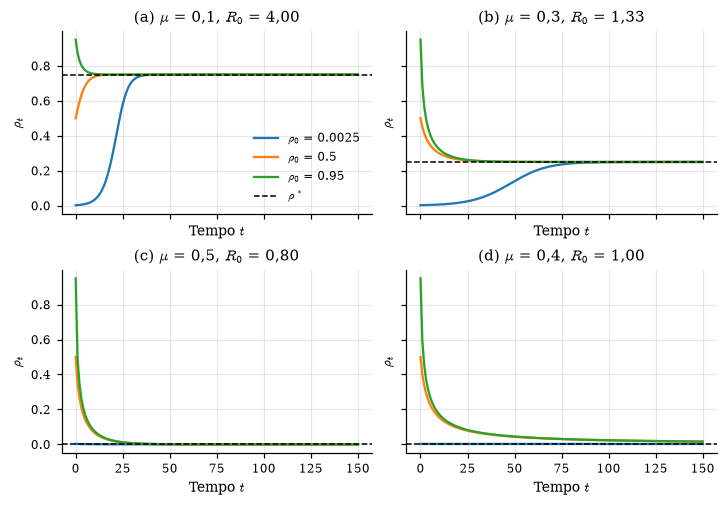

In [13]:
T_mapa = 150
rhos_0 = [N_SEEDS_INFECTED / N, 0.5, 0.95]

def iterar_mapa(rho0, mu, passos=T_mapa):
    rho = [rho0]
    for _ in range(passos):
        r = rho[-1]
        rho.append(r - mu * r + beta * k_1 * r * (1 - r))
    return np.array(rho)

fig, axs = plt.subplots(2, 2, figsize=(6.5, 4.5), sharex=True, sharey=True)

for ax, (caso, mu) in zip(axs.flat, casos_q1.items()):
    R0, rho_teo = teo_q1[caso]
    trajs = {rho0: iterar_mapa(rho0, mu) for rho0 in rhos_0}
    for rho0, traj in trajs.items():
        ax.plot(traj, label=rf'$\rho_0$ = {rho0:g}')
    ax.axhline(rho_teo, color='k', ls='--', lw=1, label=r'$\rho^*$')
    ax.set_title(f'({caso}) $\\mu$ = {fmt(mu, "g")}, $R_0$ = {fmt(R0, ".2f")}')
    ax.set_xlabel(r'Tempo $t$')
    ax.set_ylabel(r'$\rho_t$')

    c = mu * (R0 - 1)
    if R0 > 1:
        assert 0 < c < 2, f'rho* instável no caso ({caso})'
        assert abs(trajs[rhos_0[0]][-1] - rho_teo) < 1e-3, f'mapa não convergiu a rho* no caso ({caso})'

axs.flat[0].legend()
salvar_fig(fig, 'q1_mapa')

In [14]:
# Linhas da tabela de estabilidade: copiar a saída para a tabela em "2.2 Demonstração"
for caso, mu in casos_q1.items():
    R0, rho_teo = teo_q1[caso]
    c = mu * (R0 - 1)
    rho_T = iterar_mapa(rhos_0[0], mu)[-1]
    print(f"| ({caso}) | {fmt(c, '.3f')} | {fmt(1 + c, '.3f')} | {fmt(1 - c, '.3f') if R0 > 1 else '—'} "
          f"| {fmt(rho_T, '.4f')} | {fmt(rho_teo, '.3f')} |")

| (a) | 0,300 | 1,300 | 0,700 | 0,7500 | 0,750 |
| (b) | 0,100 | 1,100 | 0,900 | 0,2500 | 0,250 |
| (c) | -0,100 | 0,900 | — | 0,0000 | 0,000 |
| (d) | 0,000 | 1,000 | — | 0,0022 | 0,000 |


**Conclusão numérica.** O mapa converge para $\rho^*$ em (a) e (b) e para zero em (c) (exponencialmente) e (d) (algebricamente). A simulação concorda no regime, mas tem platô mais baixo, extinções precoces em (b) e extinção certa em (d), efeitos que o mapa determinístico não captura.


## 3. Questão 2 — Rede livre de escala
**Parâmetros:** $\gamma=2{,}5$, $N=10^4$, $\langle k\rangle\approx20\ (\pm10\%)$, $\beta=0{,}01$; (a) $\mu=0{,}1$; (b) $\mu=0{,}2$; (c) $\mu=0{,}3$.

### 3.0 Geração da rede

{'<k>': np.float64(18.38), '<k^2>': np.float64(707.013), 'k_min': np.float64(7.0), 'k_max': np.float64(174.0), 'n_comps': 1, 'lambda_1': np.float64(38.48657046133527)}


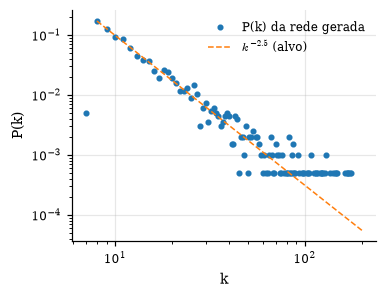

In [15]:
# Geração da rede livre de escala (configuration model "erased")
def gerar_rede_sf(N_rede, gamma=2.5, k_min=8, k_max=None, seed=SEED_BASE):
    """Sorteia N_rede graus i.i.d. de p(k) ∝ k^-gamma em [k_min, k_max] e monta a
    rede pelo configuration model; laços e arestas múltiplas são removidos."""
    if k_max is None:
        k_max = int(round(np.sqrt(N_rede * 20)))        # cutoff natural ~ sqrt(N<k>)
    ks = np.arange(k_min, k_max + 1)
    probs = ks.astype(float) ** (-gamma)
    probs /= probs.sum()

    rng_deg = np.random.default_rng(seed)
    deg_dist = rng_deg.choice(ks, size=N_rede, replace=True, p=probs)
    if deg_dist.sum() % 2:                              # soma dos graus precisa ser par
        i = rng_deg.choice(np.flatnonzero(deg_dist < k_max))
        deg_dist[i] += 1

    g = nx.Graph(nx.configuration_model(deg_dist, seed=seed))
    g.remove_edges_from(nx.selfloop_edges(g))
    return g

# Rede oficial do enunciado (N = 2*10^3, <k> ~ 20)
N_sf, k_min, k_max, gamma = 2_000, 8, 200, 2.5
G_sf = gerar_rede_sf(N_sf, gamma=gamma, k_min=k_min, k_max=k_max)
print(medir_rede(G_sf))

# P(k) medida na rede final, em log-log, com a reta k^-gamma de referência
fig_pk, ax_pk = plt.subplots(figsize=(3.4, 2.6))
hist = np.bincount([d for _, d in G_sf.degree()])
ks_med = np.nonzero(hist)[0]
ax_pk.loglog(ks_med, hist[ks_med] / N_sf, 'o', ms=3, label='P(k) da rede gerada')
kk = np.arange(k_min, k_max + 1)
probs = kk.astype(float) ** (-gamma)
probs /= probs.sum()
ax_pk.loglog(kk, probs, '--', lw=1, label=r'$k^{-2.5}$ (alvo)')
ax_pk.set_xlabel('k')
ax_pk.set_ylabel('P(k)')
ax_pk.legend()
salvar_fig(fig_pk, 'q2_pk')
plt.show()


**Rede gerada:** ⟨k⟩ = …, ⟨k²⟩ = …, k_max = …, λ₁ = …  _(método, sementes, tratamento de laços/arestas múltiplas)_

### 3.1 Experimento

In [16]:
# --- Escala de execução ------------------------------------------------------
# True  -> teste rápido, com rede pequena (para validar o código)
# False -> números oficiais do enunciado (N = 10^4, N_RUNS = 100, T = 500)
MODO_TESTE = False

if MODO_TESTE:
    N_q2, N_RUNS_q2, T_q2 = 100, 10, 200
    G_q2 = gerar_rede_sf(N_q2, gamma=gamma, k_min=k_min)
else:
    N_q2, N_RUNS_q2, T_q2 = N_sf, N_RUNS, T
    G_q2 = G_sf

medidas_q2 = medir_rede(G_q2)
print(f"N={N_q2}  <k>={medidas_q2['<k>']:.2f}  <k²>={medidas_q2['<k^2>']:.2f}  "
      f"k_min={medidas_q2['k_min']:.0f}  k_max={medidas_q2['k_max']:.0f}  "
      f"λ₁={medidas_q2['lambda_1']:.2f}  componentes={medidas_q2['n_comps']}")

beta_q2 = 0.01
casos_q2 = dict(zip(['a', 'b', 'c'], [0.1, 0.2, 0.3]))

resumos_q2, graus_sementes_q2, rho_final_q2 = {}, {}, {}

for i, (caso, mu) in enumerate(casos_q2.items()):
    arq = f'results/q2_sf_s{SEED_BASE}_N{N_q2}_mu{mu}_beta{beta_q2}_T{T_q2}_n{N_RUNS_q2}.pkl'
    if os.path.exists(arq):
        with open(arq, 'rb') as f:
            series, tempos, graus = pickle.load(f)
    else:
        series, tempos, graus = rodar_lote(
            G_q2, beta_q2, mu, rng_seed=SEED_BASE + i,
            n_runs=N_RUNS_q2, T=T_q2, return_seed_degrees=True)
        with open(arq, 'wb') as f:
            pickle.dump((series, tempos, graus), f)

    resumos_q2[caso] = resumir_execucoes(series, tempos, N_q2)
    graus_sementes_q2[caso] = np.array(graus)                        # (n_runs, n_inicial)
    rho_final_q2[caso] = np.array([s[-1] for s in series]) / N_q2    # prevalência em t = T
    print(f"({caso}) μ={mu:g}: {len(series)} execuções, "
          f"{fmt(100 * resumos_q2[caso]['frac_extintas'], '.0f')}% extintas")


N=2000  <k>=18.38  <k²>=707.01  k_min=7  k_max=174  λ₁=38.49  componentes=1
(a) μ=0.1: 100 execuções, 2% extintas
(b) μ=0.2: 100 execuções, 31% extintas
(c) μ=0.3: 100 execuções, 73% extintas


| Caso | μ | $R_0^{hom}$ | Extintas | t_ext típico | $\rho^*_{sim}$ | $\rho^*_{hom}$ | ⟨k⟩ das sementes |
|---|---|---|---|---|---|---|---|
| (a) | 0,1 | 1,84 | 2% | 10,0 | 0,421 | 0,456 | 19,7 |
| (b) | 0,2 | 0,92 | 31% | 17,8 | 0,169 | 0,000 | 19,7 |
| (c) | 0,3 | 0,61 | 73% | 21,7 | 0,048 | 0,000 | 17,7 |

| Caso | μ | $R_0^{hom}$ | Extintas | t_ext típico | $\rho^*_{sim}$ | $\rho^*_{hom}$ | ⟨k⟩ das sementes |
|---|---|---|---|---|---|---|---|
| (a) | 0,1 | 1,84 | 2% | 10,0 | 0,421 | 0,456 | 19,7 |
| (b) | 0,2 | 0,92 | 31% | 17,8 | 0,169 | 0,000 | 19,7 |
| (c) | 0,3 | 0,61 | 73% | 21,7 | 0,048 | 0,000 | 17,7 |


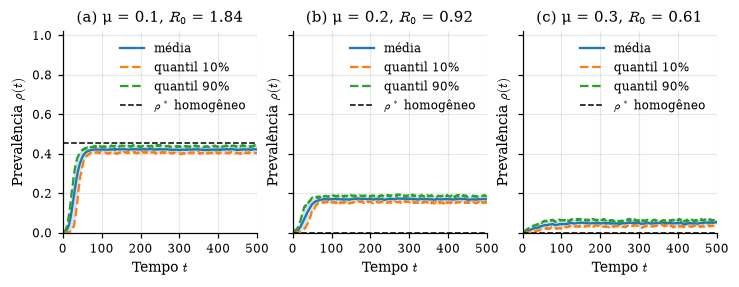

(a) corr(⟨k⟩ sementes, ρ(T)) = +0.10
(b) corr(⟨k⟩ sementes, ρ(T)) = +0.21
(c) corr(⟨k⟩ sementes, ρ(T)) = +0.09


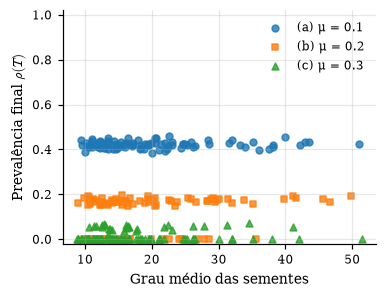

In [17]:
# Tabela resumo e ρ(t) condicionado (média + faixa p10–p90) para cada caso
fig, axs = plt.subplots(1, 3, figsize=(6.5, 2.5), sharey=True)

print("| Caso | μ | $R_0^{hom}$ | Extintas | t_ext típico | $\\rho^*_{sim}$ | $\\rho^*_{hom}$ | ⟨k⟩ das sementes |")
print("|---|---|---|---|---|---|---|---|")

for ax, (caso, mu) in zip(axs, casos_q2.items()):
    r = resumos_q2[caso]
    R0_hom = beta_q2 * medidas_q2['<k>'] / mu
    rho_hom = max(0.0, 1 - 1 / R0_hom)
    g_sem = graus_sementes_q2[caso].mean(axis=1)

    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0_hom, '.2f')} | {fmt(100 * r['frac_extintas'], '.0f')}% "
          f"| {fmt(r['tempo_tipico_extincao'], '.1f')} | {fmt(r['rho_cond_media_tavg'], '.3f')} "
          f"| {fmt(rho_hom, '.3f')} | {fmt(g_sem.mean(), '.1f')} |")

    if r['n_sobreviventes'] > 0:
        plot_rho_cond(r, ax, f'({caso}) μ = {mu:g}, $R_0$ = {R0_hom:.2f}')
    else:
        ax.set_title(f'({caso}) μ = {mu:g}, $R_0$ = {R0_hom:.2f}')
        ax.text(0.5, 0.5, 'todas as execuções extintas', transform=ax.transAxes,
                ha='center', va='center', fontsize=7, color='0.35')
    ax.axhline(rho_hom, color='k', ls='--', lw=1, label=r'$\rho^*$ homogêneo')
    ax.set_xlim(0, r['tam_serie'] - 1)
    ax.set_ylim(0, 1.02)
    ax.legend(loc='upper right')

salvar_fig(fig, 'q2_rho_cond')
plt.show()

# Prevalência final de cada execução vs. grau médio das 5 sementes
fig2, ax2 = plt.subplots(figsize=(3.4, 2.6))
marcadores = {'a': 'o', 'b': 's', 'c': '^'}

for caso in casos_q2:
    x = graus_sementes_q2[caso].mean(axis=1)
    y = rho_final_q2[caso]
    ax2.scatter(x, y, s=20, marker=marcadores[caso], alpha=0.8,
                label=f'({caso}) μ = {casos_q2[caso]:g}')
    if x.std() > 0 and y.std() > 0:
        print(f"({caso}) corr(⟨k⟩ sementes, ρ(T)) = {np.corrcoef(x, y)[0, 1]:+.2f}")
    else:
        print(f"({caso}) correlação indefinida (sem variação em x ou y)")

ax2.set_xlabel('Grau médio das sementes')
ax2.set_ylabel(r'Prevalência final $\rho(T)$')
ax2.set_ylim(-0.02, 1.02)
ax2.legend(loc='best')
salvar_fig(fig2, 'q2_sementes')
plt.show()


**Discussão.** Comportamento na média; relação com o grau dos 5 vértices iniciais; papel dos hubs: _…_

### 3.2 Teoria — indicadores de limiar
| Caso | μ | $R_0^{hom}$ | $R_0^{het}$ | $R_0^{quenched}$ | Previsão hom/het/quenched | $\rho^*_{sim}$ |
|---|---|---|---|---|---|---|
| (a) | 0,1 | 1,84 | 3,85 | 3,85 | end. / end. / end. | 0,421 |
| (b) | 0,2 | 0,92 | 1,92 | 1,92 | sub. / end. / end. | 0,169 |
| (c) | 0,3 | 0,61 | 1,28 | 1,28 | sub. / end. / end. | 0,048 |

In [18]:
# Indicadores de limiar: campo médio homogêneo, heterogêneo e quenched
k1_q2 = medidas_q2['<k>']
k2_q2 = medidas_q2['<k^2>']
lam1_q2 = medidas_q2['lambda_1']

print(f"Rede em uso: N={N_q2}, <k>={k1_q2:.2f}, <k²>={k2_q2:.2f}, λ₁={lam1_q2:.2f}")
print(f"Limiares:  hom 1/<k>={1 / k1_q2:.4f}   het <k>/<k²>={k1_q2 / k2_q2:.4f}   "
      f"quenched 1/λ₁={1 / lam1_q2:.4f}")
print()
print("| Caso | μ | $R_0^{hom}$ | $R_0^{het}$ | $R_0^{quenched}$ | Previsão hom/het/quenched | $\\rho^*_{sim}$ |")
print("|---|---|---|---|---|---|---|")


def previsao(R0):
    return 'end.' if R0 > 1 else 'sub.'


for caso, mu in casos_q2.items():
    R0_hom = beta_q2 * k1_q2 / mu
    R0_het = beta_q2 * k2_q2 / (mu * k1_q2)
    R0_q = beta_q2 * lam1_q2 / mu
    print(f"| ({caso}) | {fmt(mu, 'g')} | {fmt(R0_hom, '.2f')} | {fmt(R0_het, '.2f')} | "
          f"{fmt(R0_q, '.2f')} | {previsao(R0_hom)} / {previsao(R0_het)} / {previsao(R0_q)} | "
          f"{fmt(resumos_q2[caso]['rho_cond_media_tavg'], '.3f')} |")


Rede em uso: N=2000, <k>=18.38, <k²>=707.01, λ₁=38.49
Limiares:  hom 1/<k>=0.0544   het <k>/<k²>=0.0260   quenched 1/λ₁=0.0260

| Caso | μ | $R_0^{hom}$ | $R_0^{het}$ | $R_0^{quenched}$ | Previsão hom/het/quenched | $\rho^*_{sim}$ |
|---|---|---|---|---|---|---|
| (a) | 0,1 | 1,84 | 3,85 | 3,85 | end. / end. / end. | 0,421 |
| (b) | 0,2 | 0,92 | 1,92 | 1,92 | sub. / end. / end. | 0,169 |
| (c) | 0,3 | 0,61 | 1,28 | 1,28 | sub. / end. / end. | 0,048 |


**Discussão.** Onde os indicadores discordam (especialmente em (c)); qual descreve melhor a simulação e por quê: _…_

### 3.3 Comparação com a Questão 1 — curva $\rho^*(\lambda)$, $\lambda=\beta/\mu$
**Protocolo:** fixar $\beta$, variar $\mu$ para varrer $\lambda$ em ER e SF; marcar limiares teóricos de cada rede.

In [19]:
# Varredura de λ = β/μ: β fixa, variando μ; ER e SF na mesma escala
beta_q3 = 0.01

if MODO_TESTE:
    mus_varredura = [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]
else:
    mus_varredura = [0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]

# Rede ER equivalente (mesmo N e <k> = k_1 = 20)
G_er_q3 = nx.fast_gnp_random_graph(N_q2, k_1 / (N_q2 - 1), seed=SEED_BASE)
medidas_er_q3 = medir_rede(G_er_q3)

redes_varredura = {'ER': G_er_q3, 'SF': G_q2}
offset_seed = {'ER': 0, 'SF': 1000}
curvas = {}

for nome, G in redes_varredura.items():
    curvas[nome] = {}
    for j, mu in enumerate(mus_varredura):
        arq = (f'results/q2_curva_{nome}_s{SEED_BASE}_N{N_q2}_mu{mu}_beta{beta_q3}'
               f'_T{T_q2}_n{N_RUNS_q2}.pkl')
        if os.path.exists(arq):
            with open(arq, 'rb') as f:
                series, tempos = pickle.load(f)
        else:
            series, tempos = rodar_lote(G, beta_q3, mu,
                                        rng_seed=SEED_BASE + offset_seed[nome] + j,
                                        n_runs=N_RUNS_q2, T=T_q2)
            with open(arq, 'wb') as f:
                pickle.dump((series, tempos), f)
        curvas[nome][mu] = resumir_execucoes(series, tempos, N_q2)
    print(f"{nome}: {len(mus_varredura)} pontos de μ rodados")


ER: 11 pontos de μ rodados
SF: 11 pontos de μ rodados


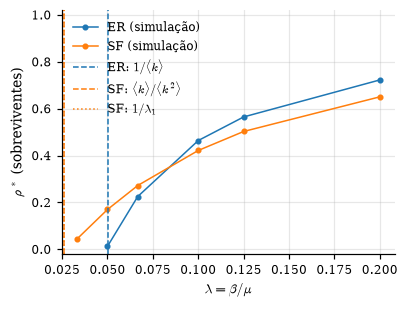

| Rede | ⟨k⟩ | ⟨k²⟩ | λ₁ | λc hom | λc het | λc quenched |
|---|---|---|---|---|---|---|
| ER | 19.94 | 417.28 | 20.97 | 0.0502 | 0.0478 | 0.0477 |
| SF | 18.38 | 707.01 | 38.49 | 0.0544 | 0.0260 | 0.0260 |


In [20]:
fig, ax = plt.subplots(figsize=(3.6, 2.7))

for nome in redes_varredura:
    mus = sorted(curvas[nome])
    lam = np.array([beta_q3 / mu for mu in mus])
    rho = np.array([curvas[nome][mu]['rho_cond_media_tavg'] for mu in mus])
    ax.plot(lam, rho, 'o-', ms=3, lw=1, label=f'{nome} (simulação)')

# limiares teóricos
ax.axvline(1 / medidas_er_q3['<k>'], color='C0', ls='--', lw=1,
           label=r'ER: $1/\langle k\rangle$')
ax.axvline(k1_q2 / k2_q2, color='C1', ls='--', lw=1,
           label=r'SF: $\langle k\rangle/\langle k^2\rangle$')
ax.axvline(1 / lam1_q2, color='C1', ls=':', lw=1,
           label=r'SF: $1/\lambda_1$')

ax.set_xlabel(r'$\lambda = \beta/\mu$')
ax.set_ylabel(r'$\rho^*$ (sobreviventes)')
ax.set_ylim(-0.02, 1.02)
ax.legend(loc='upper left')
salvar_fig(fig, 'q2_rho_lambda')
plt.show()

# Tabela dos limiares usados
print("| Rede | ⟨k⟩ | ⟨k²⟩ | λ₁ | λc hom | λc het | λc quenched |")
print("|---|---|---|---|---|---|---|")
for nome, m in [('ER', medidas_er_q3), ('SF', medidas_q2)]:
    print(f"| {nome} | {m['<k>']:.2f} | {m['<k^2>']:.2f} | {m['lambda_1']:.2f} | "
          f"{1 / m['<k>']:.4f} | {m['<k>'] / m['<k^2>']:.4f} | {1 / m['lambda_1']:.4f} |")


**Discussão.** Diferença de limiar entre topologias; diferença na forma da curva (transição abrupta vs. cauda/queda gradual); efeito de tamanho finito: _…_

### 3.4 Aprofundamento (opcional) — campo médio por grau
$\dfrac{d\rho_k}{dt}=-\mu\rho_k+\beta k(1-\rho_k)\Theta,\quad \Theta=\dfrac{1}{\langle k\rangle}\sum_k kP(k)\rho_k$

**Demonstração:** estado endêmico existe $\iff \beta/\mu>\langle k\rangle/\langle k^2\rangle$.
_…_

**Discussão:** limiar quando $N\to\infty$ para $\gamma\le3$ ($\langle k^2\rangle\to\infty$): _…_

In [21]:
# (opcional) verificação numérica: <k^2> em função de N (ou k_max) para gamma = 2.5, limiar <k>/<k^2> resultante

## 4. Questão 3 — Imunização prévia
**Rede e parâmetros:** rede da Q2, $\beta=0{,}01$, $\mu=0{,}1$. Imunizado = removido da dinâmica. Sementes sorteadas entre não imunizados.

**Critério de extinção:** fração $f$ impede o estado endêmico se, em 100 execuções, nenhuma tem infectados em $t=T=500$ (alternativa: prevalência quase-estacionária $<\varepsilon=10^{-3}$). _Declarar qual critério foi usado._

### 4.0 Estratégias

In [22]:
def imunizar_aleatoria(G: nx.Graph, n:int, rng):
    '''n vértices sorteados uniformemente.'''
    return rng.choice(list(G.nodes), size=min(n, G.number_of_nodes()), replace=False, )

def imunizar_hubs(G: nx.Graph, n: int):
	'''n vértices de maior grau (definir desempate).'''
	return sorted(G.degree(), key=lambda x: x[1], reverse=True)[:n]

def imunizar_conhecidos(G: nx.Graph, n: int, rng):
    '''Repetir n vezes: sorteia vértice uniforme, imuniza vizinho aleatório (sem repetição de imunizados).'''
    raise NotImplementedError

def extincao_total(G: nx.Graph, f, estrategia, rng_seed, **kw):
    '''Roda 100 execuções com fração f imunizada; retorna se o critério de extinção foi atingido.'''
    raise NotImplementedError

def bissecao_f(G: nx.Graph, estrategia, resolucao, rng_seed, f_lo=0.0, f_hi=1.0):
    '''Bisseção do menor f que satisfaz o critério. Registrar histórico de (f, resultado).'''
    raise NotImplementedError

### 4.1 Resultados da bisseção

In [23]:
# TODO: bisseção para (a) aleatória [resolução 0.05], (b) hubs [0.01], (c) conhecidos [0.01]
# TODO: atenção a estocasticidade da própria imunização (aleatória e conhecidos): fixar política (várias realizações de imunização por f?) e declarar

| Estratégia | $f_c$ | $n=f_c N$ | Resolução | Observações |
|---|---|---|---|---|
| (a) Aleatória | | | 0,05 | |
| (b) Hubs | | | 0,01 | |
| (c) Conhecidos | | | 0,01 | |

In [24]:
# TODO: figura: fração de execuções com infecção em T (ou rho*) em função de f, para as 3 estratégias, marcando f_c

### 4.2 Teoria
$\lambda_1(f)$ da rede residual para cada estratégia; checar $\beta\lambda_1(f)/\mu\approx1$.
Para a aleatória: $\kappa(f)=(1-f)\langle k^2\rangle/\langle k\rangle+f$, limiar $\kappa(f)=\mu/\beta$; e homogênea $f=1-1/R_0$.

| Estratégia | $f_c$ (sim) | $\beta\lambda_1(f_c)/\mu$ | $f_c$ (campo médio por grau) | $f_c$ (homogêneo) |
|---|---|---|---|---|
| Aleatória | | | | |
| Hubs | | — | — | — |
| Conhecidos | | — | — | — |

In [25]:
# TODO: calcular lambda_1(f) da rede residual em grade de f, por estratégia
# TODO: determinar f onde beta*lambda_1(f)/mu = 1 e comparar com f_c simulado
# TODO: f_c previsto por kappa(f) = mu/beta e por f = 1 - 1/R0 (aleatória)
# Figura: beta*lambda_1(f)/mu vs f (3 estratégias), linha horizontal em 1, f_c simulados marcados

**Discussão.** A extinção observada coincide com $\beta\lambda_1/\mu\approx1$? Onde e por quê (não)? Comparação aleatória: simulação × campo médio por grau × homogêneo: _…_

### 4.3 Robustez (1–2 parágrafos)
- Tolerância a falhas aleatórias × fragilidade a ataques dirigidos em redes livres de escala (percolação): _…_
- Por que a estratégia dos conhecidos fica entre as outras duas: _…_
- Limiar de percolação (SIR) × limiar do SIS (governado por $\lambda_1$): por que a diferença importa aqui: _…_

## 5. Discussão geral
- Síntese entre as questões (topologia, limiar, papel dos hubs, imunização): _…_
- Limitações: tamanho finito, extinção estocástica/dependência de $T$, escolha entre rede fixa × várias realizações, critério de extinção, resolução da bisseção: _…_
- Possíveis extensões: _…_

## Referências
- _Material de aula; artigos/livros usados (ex.: Pastor-Satorras et al., *Epidemic processes in complex networks*, RMP 2015)._

## Anexo A — Código
> O código completo está neste notebook (`.ipynb`), executável do início ao fim (*Restart & Run All*). Entregar junto ao PDF, com `requirements.txt`.

In [26]:
# Registro final de execução (tempo total, versões, semente)
import matplotlib
print(f"Tempo total: {(time.time() - T_INICIO) / 60:.1f} min")
print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| networkx", nx.__version__, "| matplotlib", matplotlib.__version__, "|", platform.platform())
print("SEED_BASE =", SEED_BASE, "| N =", N, "| T =", T, "| N_RUNS =", N_RUNS)
print("Cache em results/:", sorted(os.listdir("results")))

Tempo total: 0.1 min
Python 3.14.10 | numpy 2.5.5 | scipy 1.18.0 | networkx 3.6.1 | matplotlib 3.11.2 | Linux-7.3.5-arch1-1-x86_64-with-glibc2.44
SEED_BASE = 42 | N = 2000 | T = 500 | N_RUNS = 100
Cache em results/: ['q1_er_s42_mu0.1_0.02_T500_n100.pkl', 'q1_er_s42_mu0.3_0.02_T500_n100.pkl', 'q1_er_s42_mu0.4_0.02_T500_n100.pkl', 'q1_er_s42_mu0.5_0.02_T500_n100.pkl', 'q2_curva_ER_s42_N100_mu0.05_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N100_mu0.1_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N100_mu0.2_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N100_mu0.3_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N100_mu0.5_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N100_mu0.8_beta0.01_T200_n10.pkl', 'q2_curva_ER_s42_N2000_mu0.05_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N2000_mu0.08_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N2000_mu0.15_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N2000_mu0.1_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N2000_mu0.2_beta0.01_T500_n100.pkl', 'q2_curva_ER_s42_N2000_mu0.3_beta0.01_T500_n1

## Exportação do PDF final (célula de estudo)

1. *Restart & Run All*; conferir que não há `NotImplementedError`/`TODO` visíveis.
2. Marcar rascunhos com tag `study` e blocos de código com `hide-code` (já pré-marcados neste template).
3. Exportar, por exemplo:
```bash
jupyter nbconvert --to pdf simulacao_nb.ipynb --template-file tex/relatorio.tex.j2 --output-dir tex \
  --TagRemovePreprocessor.remove_cell_tags='{"study"}' \
  --TagRemovePreprocessor.remove_input_tags='{"hide-code"}'
```
(alternativa se não houver LaTeX: `--to html`, abrir no navegador e imprimir em PDF; ou `--to webpdf`.)
4. Conferir limite de **1 página por questão** e legibilidade das figuras.
5. Anexar o `.ipynb` + `requirements.txt` + pasta `figs/` (se pedido).

**Checklist final**
- [ ] Declaração de IA visível
- [ ] Todas as tabelas preenchidas
- [ ] Todas as figuras com eixos/legendas/unidades
- [ ] Sementes e versões informadas
- [ ] Opcionais assinalados como tal